# JS09 – Klasifikasi: Praktikum 2
## Klasifikasi Naive Bayes dengan Data Dummy

**Tujuan praktikum**

1. Membuat dataset klasifikasi sintetis dengan `make_classification`.
2. Menerapkan **Multinomial Naive Bayes** dan **Gaussian Naive Bayes** pada data yang sama.
3. Membandingkan akurasi data latih dan data uji.
4. Memahami mengapa jenis Naive Bayes harus disesuaikan dengan tipe data.
5. Menilai kestabilan hasil pada dataset berukuran sangat kecil.

**Tentang data:** Dataset dibuat sintetis dengan 30 sampel, 2 fitur, dan 2 kelas. Nilai fitur diubah menjadi bilangan bulat non-negatif agar dapat dipakai oleh `MultinomialNB`, yang secara teori ditujukan untuk data diskrit/hitungan (seperti jumlah kata). `GaussianNB` lebih sesuai untuk fitur kontinu yang berdistribusi normal.

> Pada percobaan ini, `random_state=0` ditambahkan saat membuat data agar hasil dapat direproduksi. Tanpa `random_state`, `make_classification` menggunakan sumber acak global sehingga hasil bisa berbeda setiap kali notebook dijalankan.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.base import clone

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membuat dataset dummy

Parameter `make_classification`:

- `n_samples=30` — jumlah sampel.
- `n_features=2` — jumlah fitur.
- `n_classes=2` — jumlah kelas.
- `n_informative=2` — kedua fitur informatif terhadap kelas.
- `n_redundant=0`, `n_repeated=0` — tidak ada fitur redundan atau berulang.
- `shuffle=False` — data tidak diacak saat dibuat, sehingga urutan kelas dapat terlihat.

Nilai fitur kemudian dibuat absolut, dibulatkan dua desimal, dikalikan 100, dan diubah menjadi integer. Tujuannya agar data berbentuk bilangan diskrit non-negatif.

In [2]:
X, y = make_classification(
    n_samples=30,
    n_features=2,
    n_classes=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    shuffle=False,
    random_state=0,
)

X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Distribusi kelas:", np.bincount(y))
print("\nContoh 10 baris pertama:")
print(X[:10])
print("\nLabel:")
print(y[:20])

Bentuk X: (30, 2)
Bentuk y: (30,)
Distribusi kelas: [15 15]

Contoh 10 baris pertama:
[[186 241]
 [221 213]
 [141 225]
 [133 170]
 [111  99]
 [159 136]
 [135 160]
 [130 140]
 [233 167]
 [139 152]]

Label:
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0]


### 2. Membuat DataFrame dan label kategorikal

Label asli berbentuk angka `0` dan `1`. Agar lebih mudah dibaca, label dipetakan menjadi `Kelas B` (0) dan `Kelas A` (1).

In [3]:
y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)
df = pd.DataFrame(data, columns=["Fitur 1", "Fitur 2", "Label"])
df["Label"] = df["Label"].astype(int)

labels = {1: "Kelas A", 0: "Kelas B"}
df_label = df.copy()
df_label["Label"] = df_label["Label"].map(labels)

df_label.head(10)

,Fitur 1,Fitur 2,Label
0,186,241,Kelas B
1,221,213,Kelas B
2,141,225,Kelas B
3,133,170,Kelas B
4,111,99,Kelas B
5,159,136,Kelas B
6,135,160,Kelas B
7,130,140,Kelas B
8,233,167,Kelas A
9,139,152,Kelas A


### 3. Visualisasi data

Kedua fitur dipetakan dalam bidang 2D. Warna menunjukkan kelas. Dengan hanya 30 titik, sebaran data tidak selalu memisahkan kedua kelas secara sempurna.

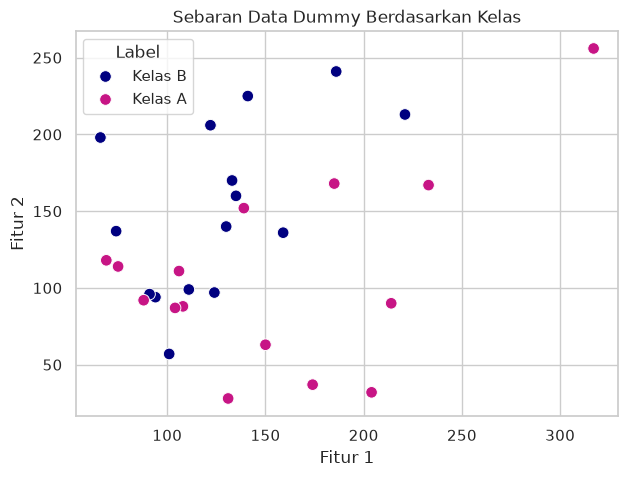

In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df_label,
    x="Fitur 1",
    y="Fitur 2",
    hue="Label",
    palette={"Kelas A": "MediumVioletRed", "Kelas B": "Navy"},
    s=70,
)
plt.title("Sebaran Data Dummy Berdasarkan Kelas")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

### 4. Pembagian data latih dan uji

Data dibagi 70% latih dan 30% uji dengan `random_state=30`, mengikuti praktikum pada modul. Karena data hanya 30 baris, data uji hanya berisi 9 baris. Komposisi kelas pada data uji bisa tidak seimbang, sehingga satu split saja tidak cukup untuk menilai performa secara stabil.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=30
)

print("Data latih :", X_train.shape[0], "baris")
print("Data uji   :", X_test.shape[0], "baris")
print("Distribusi kelas latih:", np.bincount(y_train))
print("Distribusi kelas uji  :", np.bincount(y_test))

Data latih : 21 baris
Data uji   : 9 baris
Distribusi kelas latih: [13  8]
Distribusi kelas uji  : [2 7]


### 5. Multinomial Naive Bayes

`MultinomialNB` mengasumsikan fitur berupa nilai diskrit/hitungan dan non-negatif. Data kita sudah berupa integer non-negatif, sehingga secara teknis bisa dipakai, meskipun data ini bukan data teks atau jumlah kejadian sesungguhnya.

In [6]:
mnb = MultinomialNB()
mnb.fit(X_train, y_train)

y_train_pred_mnb = mnb.predict(X_train)
y_test_pred_mnb = mnb.predict(X_test)

acc_train_mnb = accuracy_score(y_train, y_train_pred_mnb)
acc_test_mnb = accuracy_score(y_test, y_test_pred_mnb)

print(f"Akurasi data latih (Multinomial): {acc_train_mnb:.4f}")
print(f"Akurasi data uji   (Multinomial): {acc_test_mnb:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_mnb))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_test_pred_mnb, digits=3))

Akurasi data latih (Multinomial): 0.5714
Akurasi data uji   (Multinomial): 0.8889

Confusion Matrix:
[[2 0]
 [1 6]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

           0      0.667     1.000     0.800         2
           1      1.000     0.857     0.923         7

    accuracy                          0.889         9
   macro avg      0.833     0.929     0.862         9
weighted avg      0.926     0.889     0.896         9



### 6. Gaussian Naive Bayes

`GaussianNB` mengasumsikan setiap fitur berdistribusi normal (Gaussian) di dalam setiap kelas. Model ini lebih sesuai untuk fitur kontinu, bukan data hitungan diskrit.

In [7]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
y_test_pred_gnb = gnb.predict(X_test)

acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f"Akurasi data latih (Gaussian): {acc_train_gnb:.4f}")
print(f"Akurasi data uji   (Gaussian): {acc_test_gnb:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_gnb))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_test_pred_gnb, digits=3))

Akurasi data latih (Gaussian): 0.6667
Akurasi data uji   (Gaussian): 0.4444

Confusion Matrix:
[[1 1]
 [4 3]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

           0      0.200     0.500     0.286         2
           1      0.750     0.429     0.545         7

    accuracy                          0.444         9
   macro avg      0.475     0.464     0.416         9
weighted avg      0.628     0.444     0.488         9



### 7. Perbandingan hasil satu split

Tabel berikut merangkum akurasi kedua model pada split yang sama. Karena data uji hanya 9 baris, satu kesalahan saja sudah mengubah akurasi sekitar 11 poin persentase.

In [8]:
perbandingan = pd.DataFrame({
    "Model": ["MultinomialNB", "GaussianNB"],
    "Akurasi latih": [acc_train_mnb, acc_train_gnb],
    "Akurasi uji": [acc_test_mnb, acc_test_gnb],
})
perbandingan.round(4)

,Model,Akurasi latih,Akurasi uji
0,MultinomialNB,0.5714,0.8889
1,GaussianNB,0.6667,0.4444


### 8. Uji kestabilan dengan 100 pembagian data

Untuk melihat apakah hasil satu split kebetulan, kita ulangi pembagian data 100 kali dengan `random_state` berbeda. Setiap kali, kedua model dilatih pada data latih dan diuji pada data uji. Rata-rata dan simpangan baku akurasi memberi gambaran yang lebih jujur tentang performa pada dataset kecil.

In [9]:
catatan = []

for seed in range(100):
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.3, random_state=seed
    )

    for name, model in [
        ("MultinomialNB", MultinomialNB()),
        ("GaussianNB", GaussianNB()),
    ]:
        model.fit(Xtr, ytr)
        catatan.append({
            "Model": name,
            "Random state": seed,
            "Akurasi uji": model.score(Xte, yte),
        })

stabilitas = pd.DataFrame(catatan)
ringkasan_stabilitas = stabilitas.groupby("Model")["Akurasi uji"].agg(
    ["mean", "std", "min", "max"]
).round(4)
ringkasan_stabilitas

,mean,std,min,max
Model,,,,
GaussianNB,0.5744,0.1350,0.1111,0.8889
MultinomialNB,0.6756,0.1445,0.2222,1.0000


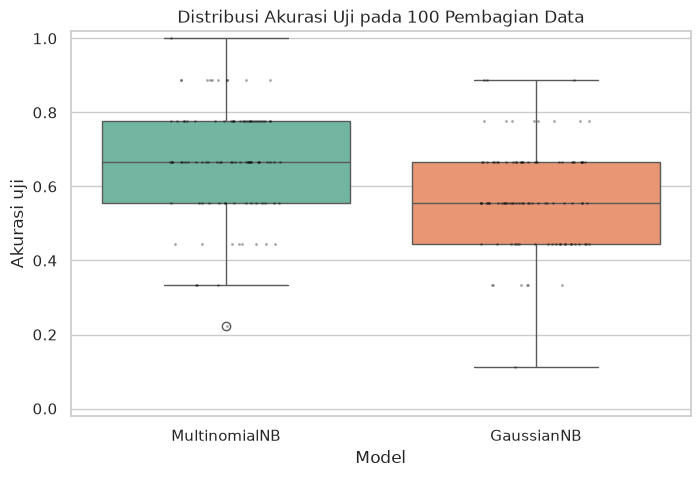

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=stabilitas,
    x="Model",
    y="Akurasi uji",
    hue="Model",
    palette="Set2",
    legend=False,
)
sns.stripplot(
    data=stabilitas,
    x="Model",
    y="Akurasi uji",
    color="black",
    size=2,
    alpha=0.35,
    jitter=0.18,
)
plt.title("Distribusi Akurasi Uji pada 100 Pembagian Data")
plt.xlabel("Model")
plt.ylabel("Akurasi uji")
plt.ylim(-0.02, 1.02)
plt.show()

### 9. Perbandingan decision boundary

Visualisasi berikut menunjukkan bagaimana kedua model membagi ruang fitur. `MultinomialNB` menghasilkan batas yang relatif lurus karena model ini pada dasarnya linear terhadap log fitur, sedangkan `GaussianNB` dapat membentuk batas yang lebih melengkung karena setiap kelas memiliki rata-rata dan variansi fitur sendiri.

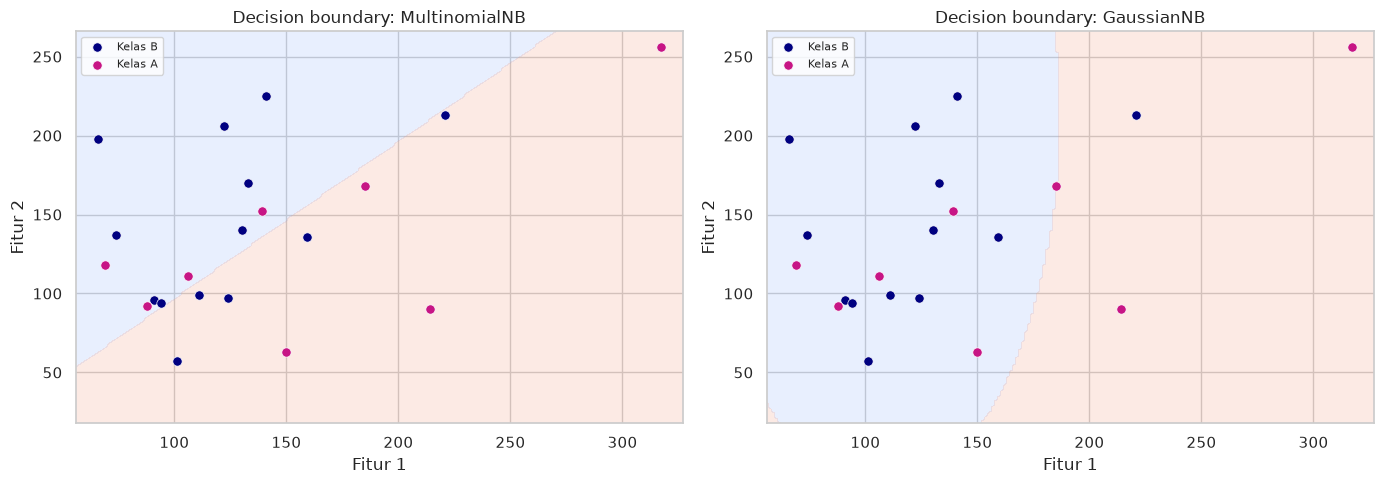

In [11]:
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 10, X[:, 0].max() + 10, 200),
    np.linspace(X[:, 1].min() - 10, X[:, 1].max() + 10, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model, ax, title in [
    (MultinomialNB(), axes[0], "MultinomialNB"),
    (GaussianNB(), axes[1], "GaussianNB"),
]:
    model.fit(X_train, y_train)
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], alpha=0.20, cmap="coolwarm")
    for label_value, label_name, color in [
        (0, "Kelas B", "Navy"),
        (1, "Kelas A", "MediumVioletRed"),
    ]:
        mask = y_train == label_value
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            c=color,
            s=45,
            edgecolor="white",
            linewidth=0.5,
            label=label_name,
        )

    ax.set_title(f"Decision boundary: {title}")
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 10. Interpretasi dan kesimpulan

**Hasil satu split (`random_state=30`)**

- `MultinomialNB`: akurasi latih sekitar **0,571**, akurasi uji sekitar **0,889**.
- `GaussianNB`: akurasi latih sekitar **0,667**, akurasi uji sekitar **0,444**.

**Hasil 100 split**

- `MultinomialNB`: rata-rata akurasi uji sekitar **0,676** dengan simpangan baku **0,144**.
- `GaussianNB`: rata-rata akurasi uji sekitar **0,574** dengan simpangan baku **0,134**.

**Mengapa hasilnya tidak stabil?**

1. Dataset hanya 30 sampel, sehingga data uji hanya 9 sampel. Perubahan satu prediksi berdampak besar pada akurasi.
2. Data dibuat dengan `n_informative=2`, tetapi sebaran kelasnya tidak selalu terpisah sempurna.
3. `MultinomialNB` dan `GaussianNB` memiliki asumsi berbeda. Pada data integer non-negatif ini, `MultinomialNB` sedikit lebih cocok, tetapi keunggulannya tidak konsisten di semua split.

**Kapan memakai masing-masing?**

- **MultinomialNB**: data diskrit/hitungan non-negatif, terutama klasifikasi teks dengan Bag of Words atau TF-IDF.
- **GaussianNB**: data kontinu yang kira-kira berdistribusi normal pada setiap kelas.
- **CategoricalNB**: data kategorikal diskrit yang bukan hitungan.

**Kesimpulan**

1. Kedua model dapat dilatih dengan API yang sama, tetapi asumsi datanya berbeda.
2. Pada percobaan ini, `MultinomialNB` memberi akurasi uji lebih tinggi pada split utama dan rata-rata 100 split, tetapi variansinya besar.
3. Dataset kecil membuat kesimpulan performa tidak boleh diambil dari satu split saja.
4. Pemilihan varian Naive Bayes harus disesuaikan dengan jenis fitur, bukan hanya dari akurasi.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS09 – Klasifikasi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi
- `scikit-learn` – Naive Bayes. https://scikit-learn.org/stable/modules/naive_bayes.html
- `scikit-learn` – Dataset generation: make_classification. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html
- Raschka, S. (2015). *Python Machine Learning*. Packt Publishing.